In [1]:
import h3
import h3coco as coco

target_cells = coco.cells_for_state('california', 7)

In [2]:
'8049fffffffffff'
'81483ffffffffff'
'824807fffffffff'

cells = (set(h3.cell_to_children('8049fffffffffff', 2)) - set(h3.cell_to_children('81483ffffffffff')) ) | {'824807fffffffff'}

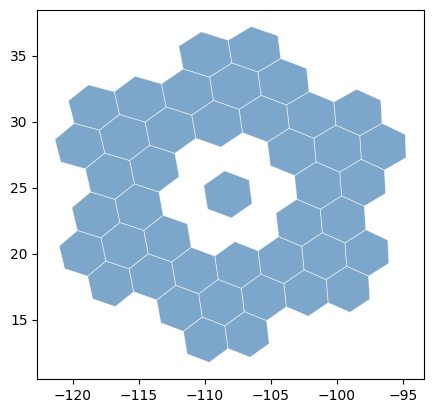

In [3]:
coco.plot_cells(cells)

In [4]:
from dataclasses import dataclass
import matplotlib.pyplot as plt

def plot_signed_cells(cells: dict[str, int], ax=None):
    """Plot cells with +1 values in blue and -1 values in red.
    
    Cells are plotted in resolution order (low to high) so larger cells appear under smaller ones.
    """
    if ax is None:
        ax = plt.gca()
    
    # Sort by resolution (ascending) so lower res cells are drawn first (underneath)
    sorted_cells = sorted(cells.items(), key=lambda kv: h3.get_resolution(kv[0]))
    
    for cell, sign in sorted_cells:
        if sign > 0:
            coco.plot_cells([cell], ax=ax, facecolor='steelblue', edgecolor='white', alpha=1.0)
        else:
            coco.plot_cells([cell], ax=ax, facecolor='indianred', edgecolor='white', alpha=1.0)
    
    return ax


@dataclass
class Janus:
    root: str  # root/parent cell
    
    child_res: int
    local_target_cells: set[str]
    pos: dict[str, int]
    neg: dict[str, int]
    
    @classmethod
    def from_cell(cls, h: str):
        """Construct a Janus from a single cell."""
        return cls(
            root = h,
            child_res = h3.get_resolution(h),
            local_target_cells = {h},
            pos = {h: 1},
            neg = {},
        )
    
    def check(self):
        for h in self.local_target_cells:
            assert h3.get_resolution(h) == self.child_res

        desc = set(h3.cell_to_children(self.root, self.child_res))
        assert self.local_target_cells <= desc

        pos = coco.co_uncompact(self.pos, self.child_res)
        neg = coco.co_uncompact(self.neg, self.child_res)
        assert len(pos & neg) == 0
        assert desc == pos | neg

    def plot(self):
        fig, (ax_pos, ax_neg) = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
        
        for ax in (ax_pos, ax_neg):
            ax.set_xticks([])
            ax.set_yticks([])
        
        plot_signed_cells(self.pos, ax=ax_pos)
        plot_signed_cells(self.neg, ax=ax_neg)        
        fig.tight_layout()
        
        return fig

In [5]:
jan = Janus(
    root = '8049fffffffffff',
    child_res = 2,
    local_target_cells = (set(h3.cell_to_children('8049fffffffffff', 2)) - set(h3.cell_to_children('81483ffffffffff')) ) | {'824807fffffffff'},
    pos = {'8049fffffffffff': 1, '81483ffffffffff': -1, '824807fffffffff': 1},
    neg = {'81483ffffffffff': 1, '824807fffffffff': -1},
)

jan.check()

In [6]:
jan = Janus.from_cell('8049fffffffffff')
jan

Janus(root='8049fffffffffff', child_res=0, local_target_cells={'8049fffffffffff'}, pos={'8049fffffffffff': 1}, neg={})

In [7]:
def from_cells(cells):
    janni = {
        c: Janus.from_cell(c)
        for c in cells
    }
    return janni

In [8]:
from collections import defaultdict

def process_children(parent: str, children: list[Janus]):
    pos = coco.ArithDict.sum(j.pos for j in children)
    neg = coco.ArithDict.sum(j.neg for j in children)

    if len(neg) + 1 < len(pos):
        pos = coco.ArithDict([parent]) - neg
        neg = neg
    else:
        pos = pos
        neg = coco.ArithDict([parent]) - pos

    jan = Janus(
        root = parent,
        child_res = children[0].child_res,
        local_target_cells = set.union(*[c.local_target_cells for c in children]),
        pos = pos,
        neg = neg,
    )

    jan.check()

    return jan

def bump(janni):
    groups = defaultdict(list)

    for c, j in janni.items():
        p = h3.cell_to_parent(c)
        groups[p].append(j)

    out = {
        h: process_children(h, children)
        for h, children in groups.items()
    }
    
    return out

In [9]:
def cocompact(cells) -> dict[str, int]:
    cells = list(cells)
    res = h3.get_resolution(cells[0])
    for c in cells:
        assert h3.get_resolution(c) == res

    janni = from_cells(cells)
    while res > 0:
        janni = bump(janni)
        res = res - 1

    out = coco.ArithDict.sum(j.pos for j in janni.values())
    out = dict(out)
    
    return out

In [10]:
cells = (set(h3.cell_to_children('8049fffffffffff', 2)) - set(h3.cell_to_children('81483ffffffffff')) ) | {'824807fffffffff'}
out = cocompact(cells)

assert coco.co_uncompact(out, 2) == cells
out

{'81483ffffffffff': -1, '8049fffffffffff': 1, '824807fffffffff': 1}

In [11]:
cells = """82481ffffffffff, 824807fffffffff, 82480ffffffffff, 824837fffffffff, 824817fffffffff, 824827fffffffff""".split(', ')

In [33]:
cells = ['82481ffffffffff',
     '824807fffffffff',
     '82480ffffffffff',
 '824837fffffffff',
 '824817fffffffff',
    h3.cell_to_center_child('824827fffffffff', 4),
        ]

cells = coco.ArithDict(cells)
cells

ArithDict({'82481ffffffffff': 1, '824807fffffffff': 1, '82480ffffffffff': 1, '824837fffffffff': 1, '824817fffffffff': 1, '8448201ffffffff': 1})

In [34]:
set(cells.keys())

{'824807fffffffff',
 '82480ffffffffff',
 '824817fffffffff',
 '82481ffffffffff',
 '824837fffffffff',
 '8448201ffffffff'}

In [43]:
cells4 = coco.co_uncompact(cells, 4)
# cells4

In [44]:
out = coco.cocompact(cells4)
out

{'81483ffffffffff': 1, '824827fffffffff': -1, '8448201ffffffff': 1}

In [49]:
coco.co_uncompact(expected, 4) == cells4

True

In [47]:
h3.cell_to_children('81483ffffffffff')

['824807fffffffff',
 '82480ffffffffff',
 '824817fffffffff',
 '82481ffffffffff',
 '824827fffffffff',
 '82482ffffffffff',
 '824837fffffffff']

In [ ]:
['824807fffffffff',
 '82480ffffffffff',
 '824817fffffffff',
 '82481ffffffffff',
 '824827fffffffff',
 '82482ffffffffff',
 '824837fffffffff']


In [48]:
expected = {'81483ffffffffff': 1, '824827fffffffff': -1, '8448201ffffffff': 1, '82482ffffffffff': -1}

In [14]:
h3.cell_to_center_child('824827fffffffff', 5)

'85482003fffffff'

In [10]:
coco.cocompact(cells)

{'81483ffffffffff': 1}

In [21]:
h = '81483ffffffffff'
cells = h3.cell_to_children(h)
# coco.cocompact(cells)

In [22]:
cells

['824807fffffffff',
 '82480ffffffffff',
 '824817fffffffff',
 '82481ffffffffff',
 '824827fffffffff',
 '82482ffffffffff',
 '824837fffffffff']

In [26]:
cells = coco.co_uncompact({'81483ffffffffff': 1, '824837fffffffff': -1}, 2)
cells

{'824807fffffffff',
 '82480ffffffffff',
 '824817fffffffff',
 '82481ffffffffff',
 '824827fffffffff',
 '82482ffffffffff'}

In [ ]:
coco.cocompact(cells)

{'81483ffffffffff': 1}